In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reading dataset
df = pd.read_csv('train.csv')

# Show first 5 lines of the dataset
df.head()


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
# Data Cleaning and Exploration
# Check how many null values are there in each column
df.isnull().sum()


PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
# Data Imputation 
# Fill with Median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill with Mode
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop Cabin column because it has highest number of empty boxes
if 'Cabin' in df.columns:
    df = df.drop(columns=['Cabin'])

# Check if data is cleaned
df.isnull().sum()


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

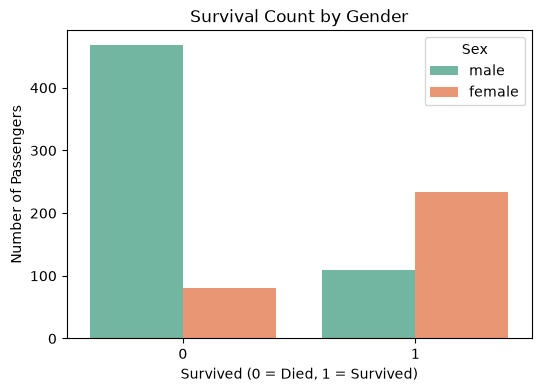

In [5]:
# Data Visualization
# Create a graph showing how many men and women survived
plt.figure(figsize=(6,4))
sns.countplot(x='Survived', hue='Sex', data=df, palette='Set2')

# Set name and label of the graph
plt.title('Survival Count by Gender')
plt.xlabel('Survived (0 = Died, 1 = Survived)')
plt.ylabel('Number of Passengers')

# Show graph
plt.show()


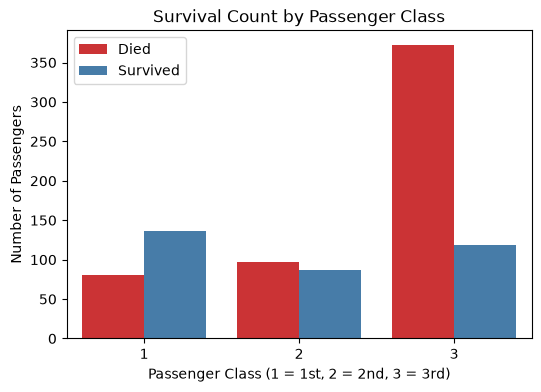

In [6]:
# See survived based on PClass
plt.figure(figsize=(6,4))
sns.countplot(x='Pclass', hue='Survived', data=df, palette='Set1')

# Set name and label of the graph
plt.title('Survival Count by Passenger Class')
plt.xlabel('Passenger Class (1 = 1st, 2 = 2nd, 3 = 3rd)')
plt.ylabel('Number of Passengers')
plt.legend(['Died', 'Survived'])

# Show graph
plt.show()


In [8]:
# Data Preparation (Machine Learning) 
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. One-Hot Encoding for categorical features
df_encoded = pd.get_dummies(df, columns=['Sex', 'Embarked'], drop_first=True)

# 2. Selecting Features (X) and Target (y)
# Drop columns (Name, Ticket No, ID) which are not needed
X = df_encoded.drop(columns=['PassengerId', 'Survived', 'Name', 'Ticket'])
y = df_encoded['Survived']

# 3. Splitting the dataset into Train and Test sets (80/20)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Training the Random Forest Classifier
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 5. Making predictions and calculating accuracy
predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print(f"Model Accuracy: {accuracy * 100:.2f}%")


Model Accuracy: 82.12%
